# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).
5. Réaliser une analyse exploratoire et des visualisations 1D, 2D et multivariées sur les vols Silver.

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.storagelevel import StorageLevel
from pyspark.errors import AnalysisException
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .getOrCreate()
)

spark.conf.set("spark.sql.shuffle.partitions", "50")
print("Session Spark active — Spark UI : http://localhost:4040")

## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [2]:
BRONZE_TABLES: dict[str, str] = {
    name: f"/lakehouse/bronze/{name}"
    for name in ("flights", "airlines", "airports", "cancellation_codes")
}

bronze_dfs = {alias: spark.read.format("delta").load(path) for alias, path in BRONZE_TABLES.items()}
for alias, df in bronze_dfs.items():
    print(f"[{alias}] {BRONZE_TABLES[alias]} -> {df.count():,} lignes | colonnes : {df.columns[:8]}")

df_bronze = bronze_dfs["flights"]
quality_columns = ["year", "month", "day", "airline", "flight_number", "origin_airport", "destination_airport", "departure_delay", "arrival_delay", "cancellation_reason"]
null_report = df_bronze.select(*[F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in quality_columns])
print("Valeurs nulles dans les colonnes principales :")
null_report.show(truncate=False)

26/11/18 09:26:29 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


[flights] /lakehouse/bronze/flights -> 5,819,079 lignes | colonnes : ['year', 'month', 'day', 'day_of_week', 'airline', 'flight_number', 'tail_number', 'origin_airport']


[airlines] /lakehouse/bronze/airlines -> 14 lignes | colonnes : ['iata_code', 'airline', '_ingested_at', '_source_dataset', '_source_file']


[airports] /lakehouse/bronze/airports -> 322 lignes | colonnes : ['iata_code', 'airport', 'city', 'state', 'country', 'latitude', 'longitude', '_ingested_at']


[cancellation_codes] /lakehouse/bronze/cancellation_codes -> 4 lignes | colonnes : ['cancellation_reason', 'cancellation_description', '_ingested_at', '_source_dataset', '_source_file']
Valeurs nulles dans les colonnes principales :


+----+-----+---+-------+-------------+--------------+-------------------+---------------+-------------+-------------------+
|year|month|day|airline|flight_number|origin_airport|destination_airport|departure_delay|arrival_delay|cancellation_reason|
+----+-----+---+-------+-------------+--------------+-------------------+---------------+-------------+-------------------+
|0   |0    |0  |0      |0            |0             |0                  |86153          |105071       |5729195            |
+----+-----+---+-------+-------------+--------------+-------------------+---------------+-------------+-------------------+



## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

Pour les vols : une date invalide ou hors de 1900–2100, une clé ou un numéro de vol manquant, une distance négative ou un indicateur annulé/dérouté invalide entraîne le rejet de la ligne. Les clés textuelles vides ou `null` sont traitées comme manquantes. Les vols annulés et les retards inconnus sont conservés sans imputation : remplacer un retard non observé par une médiane inventerait une mesure. Les doublons sont les lignes identiques sur toutes les colonnes métier normalisées, hors métadonnées d'ingestion ; `flight_id` est le SHA-256 de ces colonnes. Les clés des référentiels doivent être uniques après normalisation.

Silver conserve les motifs d'annulation, même si cette colonne est vide pour la plupart des vols : son absence est attendue pour les vols non annulés. Des indicateurs signalent les retards et motifs manquants et le week-end ; les codes A à D sont encodés en colonnes binaires, avec une colonne pour les autres codes et des valeurs nulles lorsque le motif manque. Le retard à l'arrivée est aussi signalé hors des bornes IQR et mis à l'échelle robuste selon les quartiles des vols non annulés dont le retard est connu. Les valeurs extrêmes ne sont pas supprimées.

Attention : chaque exécution réécrit `/lakehouse/silver/flights_enriched` et `/lakehouse/silver/j2_demo_delta`.

Pour l'analyse météo du projet, exécutez les cellules NOAA du notebook J1 avant J2. Elles créent les Bronze `noaa_weather_2015` (observations horaires NOAA ISD-Lite en UTC) et `weather_station_map` (station la plus proche à 25 km maximum, fuseau IANA). Silver joint chaque vol à la météo de son aéroport de départ à l'heure programmée, convertie du fuseau local vers UTC. `tail_number` est normalisé pour l'analyse de propagation au Jour 3.


In [ ]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"

narrow = df_bronze.select("airline", "arrival_delay").filter(F.col("arrival_delay").isNotNull())
wide = narrow.groupBy("airline").agg(F.avg("arrival_delay").alias("mean_arrival_delay"))
print("Transformations créées sans action (lazy evaluation).")
print("Plan narrow :")
narrow.explain("simple")
print("Plan wide : l'Exchange correspond au shuffle de l'agrégation.")
wide.explain("simple")
wide.show(5, truncate=False)

def clean_key(column):
    normalized = F.upper(F.trim(F.col(column)))
    return F.when(normalized.isin("", "NULL"), F.lit(None).cast("string")).otherwise(normalized)

def reference_table(df, key, columns):
    # Éliminer les lignes identiques avant de vérifier l’unicité des clés normalisées.
    ref = df.select(clean_key(key).alias(key), *[F.col(c) for c in columns]).filter(F.col(key).isNotNull() & (F.col(key) != "")).dropDuplicates()
    duplicates = ref.groupBy(key).count().filter(F.col("count") > 1).count()
    if duplicates:
        raise ValueError(f"Clés ambiguës dans le référentiel {key} : {duplicates}")
    return ref

airlines = reference_table(bronze_dfs["airlines"], "iata_code", ["airline"]).select(F.col("iata_code").alias("airline_key"), F.col("airline").alias("airline_name"))
airports = reference_table(bronze_dfs["airports"], "iata_code", ["airport", "city", "state", "country", "latitude", "longitude"])
cancellations = reference_table(bronze_dfs["cancellation_codes"], "cancellation_reason", ["cancellation_description"]).select(F.col("cancellation_reason").alias("cancel_key"), "cancellation_description")

try:
    noaa_weather_bronze = spark.read.format("delta").load("/lakehouse/bronze/noaa_weather_2015")
    weather_station_bronze = spark.read.format("delta").load("/lakehouse/bronze/weather_station_map")
except AnalysisException as error:
    raise ValueError("Exécutez d'abord les cellules NOAA du notebook J1 pour créer les tables Bronze météo.") from error

station_map_duplicates = (
    weather_station_bronze.groupBy("airport_code").count().filter(F.col("count") > 1).count()
)
if station_map_duplicates:
    raise ValueError(f"Le mapping météo contient {station_map_duplicates} aéroports en double.")
airport_weather_map = weather_station_bronze.select(
    F.col("airport_code").alias("weather_airport_key"),
    F.col("station_id").alias("weather_station_id"),
    F.col("station_distance_km").alias("weather_station_distance_km"),
    F.col("airport_timezone"),
)
airports = airports.join(
    F.broadcast(airport_weather_map),
    F.col("iata_code") == F.col("weather_airport_key"),
    "left",
).drop("weather_airport_key")

weather_value_columns = [
    "air_temperature_c", "dew_point_c", "sea_level_pressure_hpa", "wind_direction_deg",
    "wind_speed_mps", "sky_cover_code", "precipitation_1h_mm", "precipitation_6h_mm",
    "precipitation_1h_trace", "precipitation_6h_trace",
]
missing_weather_columns = [column for column in ["station_id", "observation_utc", *weather_value_columns] if column not in noaa_weather_bronze.columns]
if missing_weather_columns:
    raise ValueError(f"Colonnes NOAA Bronze absentes : {missing_weather_columns}")
weather_hourly = noaa_weather_bronze.select(
    F.col("station_id").cast("string").alias("weather_station_id"),
    F.col("observation_utc").cast("timestamp").alias("weather_utc_hour"),
    F.col("observation_utc").cast("timestamp").alias("weather_observation_time_utc"),
    *[F.col(column).cast("double").alias(column) for column in weather_value_columns[:8]],
    F.col("precipitation_1h_trace").cast("boolean").alias("precipitation_1h_trace"),
    F.col("precipitation_6h_trace").cast("boolean").alias("precipitation_6h_trace"),
).filter(F.col("weather_station_id").isNotNull() & F.col("weather_utc_hour").isNotNull())
duplicate_weather_hours = (
    weather_hourly.groupBy("weather_station_id", "weather_utc_hour")
    .count().filter(F.col("count") > 1).limit(1).count()
)
if duplicate_weather_hours:
    raise ValueError("Les données NOAA ont plusieurs observations par station et heure UTC.")

df_clean = df_bronze
for column in ("year", "month", "day", "day_of_week", "flight_number", "departure_delay", "arrival_delay", "distance", "cancelled", "diverted"):
    df_clean = df_clean.withColumn(column, F.expr(f"try_cast(`{column}` as int)"))
for column in ("airline", "origin_airport", "destination_airport", "cancellation_reason", "tail_number"):
    df_clean = df_clean.withColumn(column, clean_key(column))
date_text = F.format_string("%04d-%02d-%02d", F.col("year"), F.col("month"), F.col("day"))
df_clean = df_clean.withColumn("flight_date", F.try_to_timestamp(date_text, F.lit("yyyy-MM-dd")).cast("date"))
valid = F.col("flight_date").isNotNull() & F.col("year").between(1900, 2100) & F.col("flight_number").isNotNull()
for column in ("airline", "origin_airport", "destination_airport"):
    valid = valid & F.col(column).isNotNull() & (F.col(column) != "")
valid = valid & (F.col("distance").isNull() | (F.col("distance") >= 0))
valid = valid & (F.col("cancelled").isNull() | F.col("cancelled").isin(0, 1)) & (F.col("diverted").isNull() | F.col("diverted").isin(0, 1))
bronze_count = df_bronze.count()
df_clean = df_clean.filter(valid)
valid_count = df_clean.count()
# L’empreinte du vol repose sur les valeurs métier et conserve les champs nuls.
# Les métadonnées sont exclues pour que l’identifiant soit stable lors d’une réingestion.
source_columns = [c for c in df_bronze.columns if not c.startswith("_")]
df_clean = df_clean.withColumn("flight_id", F.sha2(F.to_json(F.struct(*[F.col(c) for c in source_columns]), {"ignoreNullFields": "false"}), 256))
# Les comptages, les quartiles et les jointures réutilisent les vols dédoublonnés.
df_unique = df_clean.dropDuplicates(["flight_id"]).persist(StorageLevel.DISK_ONLY)

try:
    count_before_join = df_unique.count()
    print(f"Lignes Bronze : {bronze_count:,} | invalides : {bronze_count - valid_count:,} | doublons exacts : {valid_count - count_before_join:,}")
    # Calculer les seuils IQR et l’échelle robuste sur les vols non annulés au retard connu.
    quantiles = df_unique.filter((F.col("cancelled") == 0) & F.col("arrival_delay").isNotNull()).approxQuantile("arrival_delay", [0.25, 0.5, 0.75], 0.0001)
    if len(quantiles) != 3 or quantiles[2] <= quantiles[0]:
        raise ValueError("Impossible de calculer les indicateurs robustes : quartiles absents ou IQR nul.")
    q1, median, q3 = quantiles
    iqr = q3 - q1
    print(f"Retard à l'arrivée : Q1 = {q1}, médiane = {median}, Q3 = {q3}, IQR = {iqr} minutes.")
    airport_details = (
        "city", "state", "country", "latitude", "longitude", "weather_station_id",
        "weather_station_distance_km", "airport_timezone",
    )
    origin = airports.select(F.col("iata_code").alias("origin_key"), F.col("airport").alias("origin_airport_name"), *[F.col(c).alias(f"origin_{c}") for c in airport_details])
    destination = airports.select(F.col("iata_code").alias("destination_key"), F.col("airport").alias("destination_airport_name"), *[F.col(c).alias(f"destination_{c}") for c in airport_details])
    # Les jointures à gauche conservent les vols sans correspondance dans les référentiels.
    df_silver = (
        df_unique.join(F.broadcast(airlines), df_unique.airline == airlines.airline_key, "left").drop("airline_key")
        .join(F.broadcast(origin), F.col("origin_airport") == F.col("origin_key"), "left").drop("origin_key")
        .join(F.broadcast(destination), F.col("destination_airport") == F.col("destination_key"), "left").drop("destination_key")
        .join(F.broadcast(cancellations), F.col("cancellation_reason") == F.col("cancel_key"), "left").drop("cancel_key")
        .withColumn("is_arrival_delayed_15min", F.when(F.col("arrival_delay").isNotNull(), F.col("arrival_delay") >= 15))
        .withColumn("delay_per_100_miles", F.when(F.col("distance") > 0, F.col("arrival_delay") * 100.0 / F.col("distance")))
        .withColumn("arrival_delay_missing", F.col("arrival_delay").isNull())
        .withColumn("departure_delay_missing", F.col("departure_delay").isNull())
        .withColumn("cancellation_reason_missing", F.col("cancellation_reason").isNull())
        .withColumn("is_weekend", F.dayofweek("flight_date").isin(1, 7))
        .withColumn("arrival_delay_outlier_iqr", F.when(F.col("arrival_delay").isNotNull(), (F.col("arrival_delay") < q1 - 1.5 * iqr) | (F.col("arrival_delay") > q3 + 1.5 * iqr)))
        .withColumn("arrival_delay_robust_scaled", F.when(F.col("arrival_delay").isNotNull(), (F.col("arrival_delay") - median) / iqr))
    )
    # Un indicateur nul signale un motif inconnu. Un zéro indique un autre motif renseigné.
    for code in ("A", "B", "C", "D"):
        df_silver = df_silver.withColumn(f"cancellation_reason_is_{code}", F.when(F.col("cancellation_reason").isNotNull(), (F.col("cancellation_reason") == code).cast("int")))
    df_silver = df_silver.withColumn("cancellation_reason_is_other", F.when(F.col("cancellation_reason").isNotNull(), (~F.col("cancellation_reason").isin("A", "B", "C", "D")).cast("int")))

    # La météo est horodatée en UTC; l'heure programmée est locale à l'aéroport de départ.
    scheduled_raw = F.trim(F.col("scheduled_departure").cast("string"))
    scheduled_digits = F.regexp_replace(scheduled_raw, r"\.0+$", "")
    scheduled_hhmm = F.lpad(scheduled_digits, 4, "0")
    scheduled_2400 = (scheduled_hhmm == "2400") | scheduled_raw.rlike(r"^24:00$")
    valid_scheduled_hhmm = scheduled_hhmm.rlike(r"^(?:[01][0-9]|2[0-3])[0-5][0-9]$")
    colon_hour = F.regexp_extract(scheduled_raw, r"([01]?[0-9]|2[0-3]):([0-5][0-9])", 1)
    colon_minute = F.regexp_extract(scheduled_raw, r"([01]?[0-9]|2[0-3]):([0-5][0-9])", 2)
    scheduled_hour = F.when(scheduled_2400, F.lit(0)).otherwise(
        F.coalesce(F.when(valid_scheduled_hhmm, F.substring(scheduled_hhmm, 1, 2).cast("int")),
                   F.when(colon_hour != "", colon_hour.cast("int")))
    )
    scheduled_minute = F.when(scheduled_2400, F.lit(0)).otherwise(
        F.coalesce(F.when(valid_scheduled_hhmm, F.substring(scheduled_hhmm, 3, 2).cast("int")),
                   F.when(colon_minute != "", colon_minute.cast("int")))
    )
    local_schedule_date = F.when(scheduled_2400, F.date_add("flight_date", 1)).otherwise(F.col("flight_date"))
    local_schedule_text = F.concat(
        F.date_format(local_schedule_date, "yyyy-MM-dd"),
        F.format_string(" %02d:%02d:00", scheduled_hour, scheduled_minute),
    )
    local_schedule_timestamp = F.try_to_timestamp(local_schedule_text, F.lit("yyyy-MM-dd HH:mm:ss"))
    scheduled_departure_utc_hour = F.date_trunc(
        "hour", F.to_utc_timestamp(local_schedule_timestamp, F.col("origin_airport_timezone"))
    )
    df_silver = (
        df_silver.withColumn("scheduled_departure_utc_hour", scheduled_departure_utc_hour)
        .join(
            weather_hourly,
            (F.col("origin_weather_station_id") == F.col("weather_station_id"))
            & (F.col("scheduled_departure_utc_hour") == F.col("weather_utc_hour")),
            "left",
        )
        .drop("weather_station_id", "weather_utc_hour")
    )
    print("Plan de jointure :")
    df_silver.explain("simple")
    df_silver.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(SILVER_MAIN_PATH)
finally:
    df_unique.unpersist()

silver = spark.read.format("delta").load(SILVER_MAIN_PATH)
silver_count = silver.count()
assert silver_count == count_before_join, f"Cardinalité modifiée : {count_before_join:,} avant, {silver_count:,} après jointure."
print(f"Table Silver : {silver_count:,} lignes ; cardinalité préservée.")
silver.select(*[F.round(F.avg(F.col(c).isNotNull().cast("double")) * 100, 2).alias(c + "_match_pct") for c in ("airline_name", "origin_airport_name", "destination_airport_name")]).show(truncate=False)
# Mesurer la couverture du référentiel des motifs sur les seuls vols annulés.
silver.filter(F.col("cancelled") == 1).select(F.round(F.avg(F.col("cancellation_description").isNotNull().cast("double")) * 100, 2).alias("cancellation_match_pct")).show(truncate=False)

## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Sur une petite table de démonstration séparée, tentez d'insérer (`mode("append")`) un DataFrame au schéma incompatible et interceptez l'exception levée par Delta Lake, sans modifier la table analytique.

In [4]:
spark.read.text(f"{SILVER_MAIN_PATH}/_delta_log/00000000000000000000.json").show(8, truncate=110)

# La démonstration transactionnelle utilise une petite copie pour préserver la table analytique.
SILVER_DEMO_PATH = "/lakehouse/silver/j2_demo_delta"
sample_df = silver.select("flight_id", "flight_date", "airline", "arrival_delay")
sample_rows = sample_df.limit(3).collect()
assert len(sample_rows) == 3, "Au moins trois vols sont nécessaires pour la démonstration Delta."
demo_initial = spark.createDataFrame(sample_rows[:2], sample_df.schema).withColumn("demo_status", F.lit("initial"))
demo_initial.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(SILVER_DEMO_PATH)
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_DEMO_PATH)
except AnalysisException as error:
    if "schema" not in str(error).lower():
        raise
    print("Schema Enforcement validé : écriture incompatible refusée.")
else:
    raise AssertionError("L'écriture avec un schéma incompatible aurait dû échouer.")

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1794932361538,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"60f8468a-8992-49e4-902a-06d5ced7b4c0","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00000-194fdc70-9280-445a-ba8b-02cc0690b1a2-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00001-f6d16910-91c0-442a-aa0e-f0c366490251-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00002-5a4db223-795c-4440-8f37-0ef0e36d7d31-c000.snappy.parquet","partition

Schema Enforcement validé : écriture incompatible refusée.


### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez trois vols de la table Silver et créez une petite table Delta de démonstration avec les deux premiers. Appliquez un **`MERGE INTO`** : mise à jour du deuxième et insertion du troisième.
2. Affichez l'historique et comparez la version avant le MERGE à la version courante. La table analytique principale reste inchangée.

In [5]:
target_delta = DeltaTable.forPath(spark, SILVER_DEMO_PATH)
version_before = target_delta.history(1).select("version").first()[0]
updates = spark.createDataFrame(sample_rows[1:], sample_df.schema).withColumn("demo_status", F.lit("merge"))
(target_delta.alias("target").merge(updates.alias("source"), "target.flight_id = source.flight_id")
    .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())

history_df = target_delta.history()
history_df.select("version", "timestamp", "operation", "operationMetrics").show(truncate=80)
before = spark.read.format("delta").option("versionAsOf", version_before).load(SILVER_DEMO_PATH)
after = spark.read.format("delta").load(SILVER_DEMO_PATH)
before_status = {row.flight_id: row.demo_status for row in before.select("flight_id", "demo_status").collect()}
after_status = {row.flight_id: row.demo_status for row in after.select("flight_id", "demo_status").collect()}
assert len(before_status) == 2 and len(after_status) == 3
assert before_status[sample_rows[1].flight_id] == "initial" and after_status[sample_rows[1].flight_id] == "merge"
assert sample_rows[2].flight_id not in before_status and after_status[sample_rows[2].flight_id] == "merge"
print(f"Time Travel : version {version_before} = 2 lignes ; version courante = 3 lignes (1 mise à jour, 1 insertion).")

26/11/18 09:29:37 WARN MapPartitionsRDD: RDD 409 was locally checkpointed, its lineage has been truncated and cannot be recomputed after unpersisting


+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                operationMetrics|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|      3|2026-11-18 09:29:36.629|    MERGE|{numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetBytesRemoved -...|
|      2|2026-11-18 09:29:16.815|    WRITE|{numFiles -> 3, numRemovedFiles -> 2, numRemovedBytes -> 3835, numOutputRows ...|
|      1|2026-11-17 16:21:01.017|    MERGE|{numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetBytesRemoved -...|
|      0|2026-11-17 16:20:53.377|    WRITE|{numFiles -> 3, numRemovedFiles -> 0, numRemovedBytes -> 0, numOutputRows -> ...|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+


Time Travel : version 2 = 2 lignes ; version courante = 3 lignes (1 mise à jour, 1 insertion).


## 4. Diagnostic complémentaire et analyse exploratoire (EDA)

Cette section adapte les nouvelles consignes du professeur aux vols. Elle lit Silver sans la réécrire. Les statistiques et profils par compagnie sont calculés sur l'ensemble des données avec Spark ; les graphiques individuels utilisent un échantillon aléatoire reproductible et plafonné avant transfert vers Pandas.

Un retard inconnu, notamment pour un vol annulé, n'est pas assimilé à zéro ni imputé. L'association entre absence de retard et annulation est observable, mais elle ne prouve pas à elle seule un mécanisme MCAR, MAR ou MNAR. Un zéro n'est pas automatiquement une valeur manquante. Les valeurs extrêmes sont signalées, pas supprimées.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
silver_eda = spark.read.format("delta").load("/lakehouse/silver/flights_enriched")
print("Retards manquants selon le statut d'annulation :")
silver_eda.groupBy("cancelled").agg(
    F.count("*").alias("vols"),
    F.sum(F.col("arrival_delay").isNull().cast("long")).alias("arrivee_manquante"),
    F.sum(F.col("departure_delay").isNull().cast("long")).alias("depart_manquant"),
).orderBy("cancelled").show()
print("Distances manquantes, zéros et dates Epoch (un zéro n'est pas automatiquement manquant) :")
silver_eda.agg(
    F.sum(F.col("distance").isNull().cast("long")).alias("distance_manquante"),
    F.sum((F.col("distance") == 0).cast("long")).alias("distance_zero"),
    F.sum((F.col("flight_date") == F.lit("1970-01-01").cast("date")).cast("long")).alias("dates_epoch"),
).show()
print("Valeurs textuelles vides ou 'null' dans les clés Bronze :")
bronze_eda = spark.read.format("delta").load("/lakehouse/bronze/flights")
keys = ("airline", "origin_airport", "destination_airport")
bronze_eda.select(*[
    F.sum((F.col(c).isNotNull() & F.lower(F.trim(F.col(c))).isin("", "null")).cast("long")).alias(c)
    for c in keys
]).show()

observed = silver_eda.filter((F.col("cancelled") == 0) & F.col("arrival_delay").isNotNull())
stats = observed.agg(
    F.count("*").alias("n"),
    *[F.avg(c).alias(c + "_mean") for c in ("departure_delay", "arrival_delay", "distance")],
    *[F.stddev(c).alias(c + "_std") for c in ("departure_delay", "arrival_delay", "distance")],
    *[F.percentile_approx(c, [0.25, 0.5, 0.75], 10000).alias(c + "_q") for c in ("departure_delay", "arrival_delay", "distance")],
).first()
print(f"Vols non annulés avec retard à l'arrivée connu : {stats['n']:,}")
if stats['n'] < 2:
    raise ValueError("Au moins deux vols observés sont nécessaires pour l'analyse.")
summary = []
for column in ("departure_delay", "arrival_delay", "distance"):
    q1, median, q3 = stats[column + "_q"]
    summary.append({"variable": column, "moyenne": stats[column + "_mean"], "écart-type": stats[column + "_std"], "médiane": median, "Q1": q1, "Q3": q3, "IQR": q3 - q1})
display(pd.DataFrame(summary).round(2))
q1, median, q3 = stats["arrival_delay_q"]
iqr = q3 - q1
mean_delay, std_delay = stats["arrival_delay_mean"], stats["arrival_delay_std"]
if iqr <= 0 or std_delay is None or std_delay <= 0:
    raise ValueError("Impossible de comparer IQR et Z-score : dispersion nulle ou absente.")
print("Valeurs extrêmes du retard à l'arrivée : IQR contre Z-score (aucune suppression)")
observed.agg(
    F.sum(((F.col("arrival_delay") < q1 - 1.5 * iqr) | (F.col("arrival_delay") > q3 + 1.5 * iqr)).cast("long")).alias("hors_bornes_iqr"),
    F.sum((F.abs((F.col("arrival_delay") - mean_delay) / std_delay) > 3).cast("long")).alias("z_score_absolu_sup_3"),
).show()
print(f"Mise à l'échelle robuste : (retard - {median}) / {iqr} ; médiane et IQR calculés sur les vols observés.")

Retards manquants selon le statut d'annulation :
+---------+-------+-----------------+---------------+
|cancelled|   vols|arrivee_manquante|depart_manquant|
+---------+-------+-----------------+---------------+
|        0|5729195|            15187|              0|
|        1|  89884|            89884|          86153|
+---------+-------+-----------------+---------------+

Distances manquantes, zéros et dates Epoch (un zéro n'est pas automatiquement manquant) :
+------------------+-------------+-----------+
|distance_manquante|distance_zero|dates_epoch|
+------------------+-------------+-----------+
|                 0|            0|          0|
+------------------+-------------+-----------+

Valeurs textuelles vides ou 'null' dans les clés Bronze :


+-------+--------------+-------------------+
|airline|origin_airport|destination_airport|
+-------+--------------+-------------------+
|      0|             0|                  0|
+-------+--------------+-------------------+



Vols non annulés avec retard à l'arrivée connu : 5,714,008


,variable,moyenne,écart-type,médiane,Q1,Q3,IQR
0,departure_delay,9.29,36.89,-2,-5,7,12
1,arrival_delay,4.41,39.27,-5,-13,8,21
2,distance,824.46,608.66,650,373,1065,692


Valeurs extrêmes du retard à l'arrivée : IQR contre Z-score (aucune suppression)
+---------------+--------------------+
|hors_bornes_iqr|z_score_absolu_sup_3|
+---------------+--------------------+
|         512002|              110956|
+---------------+--------------------+

Mise à l'échelle robuste : (retard - -5) / 21 ; médiane et IQR calculés sur les vols observés.


#### Qualité des données et valeurs extrêmes

Le retard à l’arrivée manque pour les **89 884 vols annulés** (100 %) et pour **15 187 vols non annulés** (0,27 %). Le retard au départ manque pour 95,85 % des vols annulés. Le statut d’annulation est donc fortement lié à la disponibilité des mesures. L’analyse de ponctualité porte sur les **5 714 008 vols non annulés dont le retard à l’arrivée est renseigné**. Les contrôles n’ont relevé aucune distance manquante ou égale à zéro, ni date au 1er janvier 1970 dans Silver. Aucune des trois clés Bronze contrôlées ne contient de chaîne vide ou de valeur textuelle `null` après normalisation.

La moitié centrale des retards à l’arrivée s’étend de **−13 à +8 min** (IQR de 21 min). La règle des 1,5 IQR signale **512 002 vols (8,96 %)**, contre **110 956 (1,94 %)** avec un Z-score absolu supérieur à 3. La longue traîne des grands retards augmente l’écart-type et élargit le seuil du Z-score. La médiane et l’IQR décrivent le comportement courant, tandis que le taux au seuil de 15 min mesure la fréquence d’un retard opérationnel.

### 4.1 Distributions 1D et tri croisé

Histogramme des retards à l'arrivée, volume par compagnie et proportion de vols en retard d'au moins 15 minutes. Le tri croisé compare jours ouvrés et week-ends ; seuls les vols non annulés dont le retard à l'arrivée est connu sont inclus. L'histogramme est limité à −60 à 180 minutes pour la lisibilité ; les statistiques restent calculées sur tous les vols observés.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Échantillon reproductible pour les graphiques individuels : 11,462 vols (plafond 15 000).
Tri croisé : pourcentage de vols par jour ouvré / week-end et statut d'arrivée


is_late,Moins de 15 min,15 min ou plus
is_weekend,,
Jour ouvré,80.90,19.10
Week-end,82.76,17.24


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


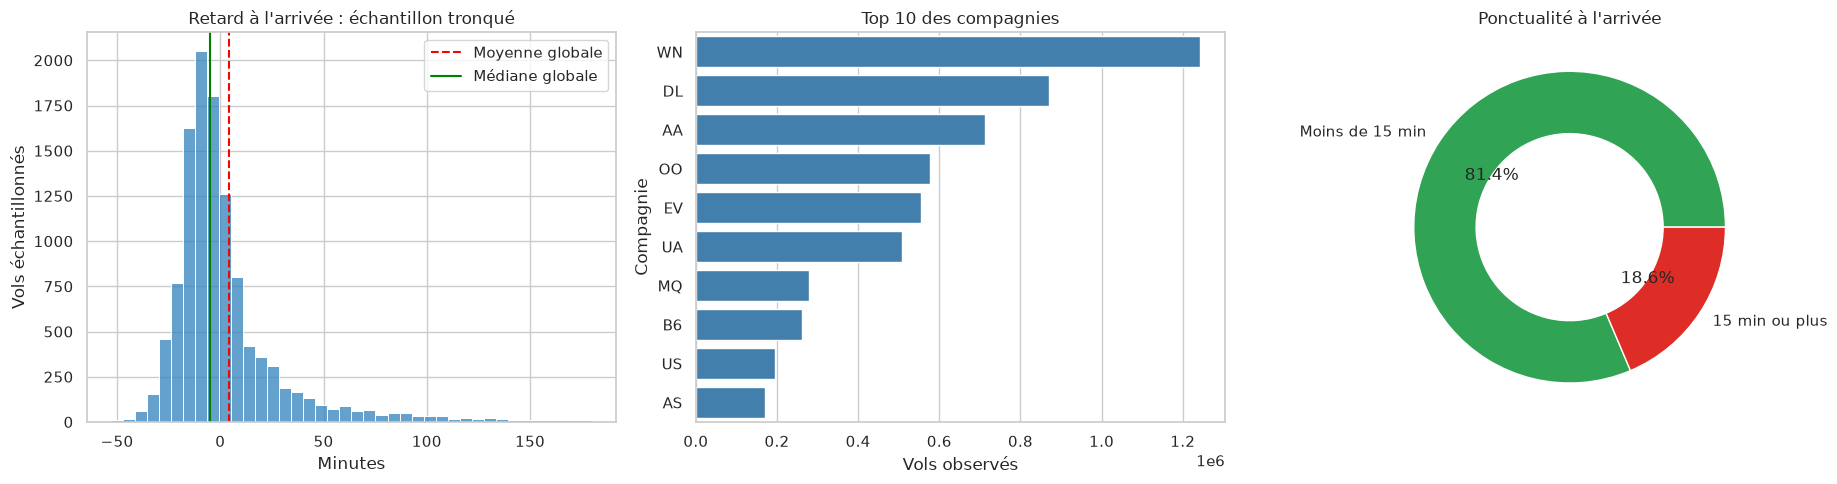

In [7]:
eda_flights = observed.withColumn("is_weekend", F.dayofweek("flight_date").isin(1, 7)).withColumn("is_late", F.col("arrival_delay") >= 15)
sample_pd = (eda_flights.select("flight_date", "airline", "distance", "departure_delay", "arrival_delay", "is_weekend", "is_late")
    .dropna(subset=["distance", "departure_delay", "arrival_delay"])
    .sample(fraction=0.002, seed=42).limit(15000).toPandas())
if len(sample_pd) < 10:
    raise ValueError("Échantillon EDA insuffisant : au moins 10 vols complets sont nécessaires.")
print(f"Échantillon reproductible pour les graphiques individuels : {len(sample_pd):,} vols (plafond 15 000).")
cross = eda_flights.groupBy("is_weekend", "is_late").count().toPandas()
cross_table = cross.pivot(index="is_weekend", columns="is_late", values="count").fillna(0)
cross_pct = cross_table.div(cross_table.sum(axis=1), axis=0).mul(100).round(2)
print("Tri croisé : pourcentage de vols par jour ouvré / week-end et statut d'arrivée")
display(cross_pct.rename(index={False: "Jour ouvré", True: "Week-end"}, columns={False: "Moins de 15 min", True: "15 min ou plus"}))
carrier_counts = eda_flights.groupBy("airline").count().orderBy(F.desc("count")).limit(10).toPandas()
late_counts = eda_flights.groupBy("is_late").count().toPandas().set_index("is_late")["count"].reindex([False, True], fill_value=0)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.histplot(sample_pd.loc[sample_pd["arrival_delay"].between(-60, 180), "arrival_delay"], bins=40, ax=axes[0], color="#3182bd")
axes[0].axvline(stats["arrival_delay_mean"], color="red", linestyle="--", label="Moyenne globale")
axes[0].axvline(median, color="green", label="Médiane globale")
axes[0].set(title="Retard à l'arrivée : échantillon tronqué", xlabel="Minutes", ylabel="Vols échantillonnés")
axes[0].legend()
sns.barplot(data=carrier_counts, x="count", y="airline", color="#3182bd", ax=axes[1])
axes[1].set(title="Top 10 des compagnies", xlabel="Vols observés", ylabel="Compagnie")
axes[2].pie(late_counts, labels=["Moins de 15 min", "15 min ou plus"], autopct="%1.1f%%", colors=["#31a354", "#de2d26"], wedgeprops={"width": 0.4})
axes[2].set_title("Ponctualité à l'arrivée")
plt.tight_layout()
plt.show()

#### Ponctualité, calendrier et volume par compagnie

L’échantillon compte **11 462 vols** avant la restriction de l’histogramme à l’intervalle de −60 à 180 min. La distribution affichée est concentrée autour de zéro et s’étire vers les retards positifs. Sur l’ensemble des vols observés, la médiane de **−5 min** correspond à une arrivée typique en avance. La moyenne de **+4,41 min** reflète le poids des retards importants.

**18,6 %** des vols observés arrivent avec au moins 15 min de retard. Le taux atteint **19,10 %** du lundi au vendredi et **17,24 %** le week-end, soit un écart brut de **1,86 point de pourcentage**. La comparaison agrège toutes les compagnies et liaisons. WN, DL et AA enregistrent les plus grands volumes de vols observés et pèsent donc davantage dans le taux global.

### 4.2 Segmentation, discrétisation et graphiques 2D

Les volumes et taux mensuels sont calculés par Spark et triés chronologiquement. Les tranches fixes de retard au départ (`cut`), les quartiles de distance (`qcut`) et les boîtes par compagnie utilisent l'échantillon ; les liens observés ne démontrent pas une causalité.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Retard à l'arrivée par tranche de départ (échantillon) :


,vols,retard_median,retard_15min_pct
tranche_depart,,,
En avance,6455,-10.0,2.79
0–14 min,2903,-1.0,10.71
15–59 min,1429,24.0,71.66
60 min ou plus,675,93.0,100.00


Quartiles de distance (échantillon) :


,vols,retard_median
quartile_distance,,
"(30.999, 370.0]",2891,-4.0
"(370.0, 649.0]",2845,-4.0
"(649.0, 1061.0]",2864,-5.0
"(1061.0, 4983.0]",2862,-6.0


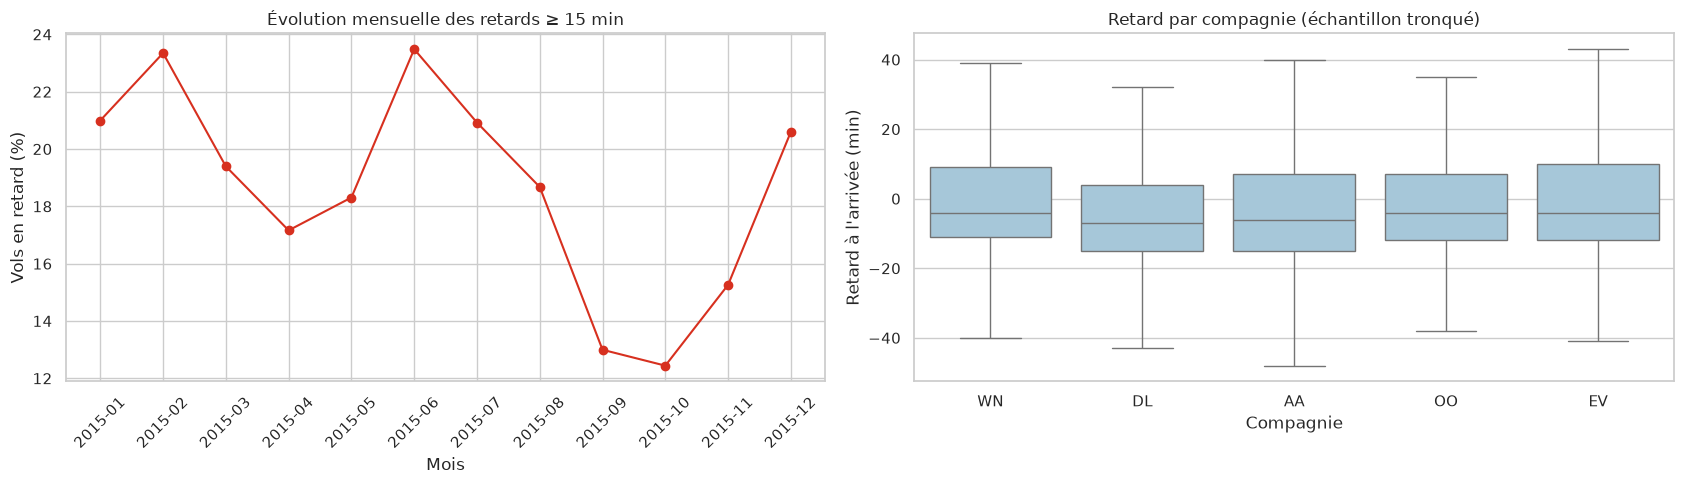

In [8]:
monthly_pd = (eda_flights.groupBy(F.date_format("flight_date", "yyyy-MM").alias("mois"))
    .agg(F.count("*").alias("vols"), (100 * F.avg(F.col("is_late").cast("double"))).alias("retard_pct"))
    .orderBy("mois").toPandas())
sample_pd["tranche_depart"] = pd.cut(sample_pd["departure_delay"], bins=[-np.inf, 0, 15, 60, np.inf], labels=["En avance", "0–14 min", "15–59 min", "60 min ou plus"], right=False)
sample_pd["quartile_distance"] = pd.qcut(sample_pd["distance"], q=4, duplicates="drop")
print("Retard à l'arrivée par tranche de départ (échantillon) :")
display(sample_pd.groupby("tranche_depart", observed=True).agg(vols=("arrival_delay", "size"), retard_median=("arrival_delay", "median"), retard_15min_pct=("is_late", lambda x: 100 * x.mean())).round(2))
print("Quartiles de distance (échantillon) :")
display(sample_pd.groupby("quartile_distance", observed=True).agg(vols=("distance", "size"), retard_median=("arrival_delay", "median")).round(2))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(monthly_pd["mois"], monthly_pd["retard_pct"], marker="o", color="#d7301f")
axes[0].set(title="Évolution mensuelle des retards ≥ 15 min", xlabel="Mois", ylabel="Vols en retard (%)")
axes[0].tick_params(axis="x", rotation=45)
top_airlines = carrier_counts.head(5)["airline"].tolist()
box_sample = sample_pd[sample_pd["airline"].isin(top_airlines) & sample_pd["arrival_delay"].between(-60, 180)]
sns.boxplot(data=box_sample, x="airline", y="arrival_delay", order=top_airlines, ax=axes[1], color="#9ecae1", showfliers=False)
axes[1].set(title="Retard par compagnie (échantillon tronqué)", xlabel="Compagnie", ylabel="Retard à l'arrivée (min)")
plt.tight_layout()
plt.show()

#### Variations mensuelles et profils de retard

En **2015**, la part des retards d’au moins 15 min atteint environ **23,5 % en juin**, tombe à **12,4 % en octobre**, puis remonte à **20,6 % en décembre**. L’écart entre juin et octobre dépasse 11 points. La courbe couvre une seule année, ce qui limite l’interprétation de ces fluctuations comme un cycle saisonnier.

Dans l’échantillon, **2,79 %** des vols partis en avance arrivent avec au moins 15 min de retard. Cette part passe à **71,66 %** pour les départs retardés de 15 à 59 min. Les **675 vols** partis avec au moins 60 min de retard atteignent tous le seuil à l’arrivée, avec un retard médian de **93 min**. Les médianes des quatre groupes de distance restent proches, de −4 à −6 min.

Les boîtes des cinq compagnies les plus représentées se recouvrent largement. DL affiche la médiane la plus basse dans ce graphique. La comparaison porte sur la partie centrale des retards dans l’échantillon tronqué, avec les valeurs hors moustaches masquées.

### 4.3 Corrélations, graphiques multidimensionnels et ACP

Pearson mesure la relation linéaire et Spearman la relation monotone sur les rangs : corrélation ne signifie pas causalité. Le pairplot utilise un sous-échantillon ; le bubble plot et l'ACP utilisent les profils agrégés de toutes les compagnies. Les six variables de l'ACP sont standardisées ; la taille des bulles représente le nombre de vols.

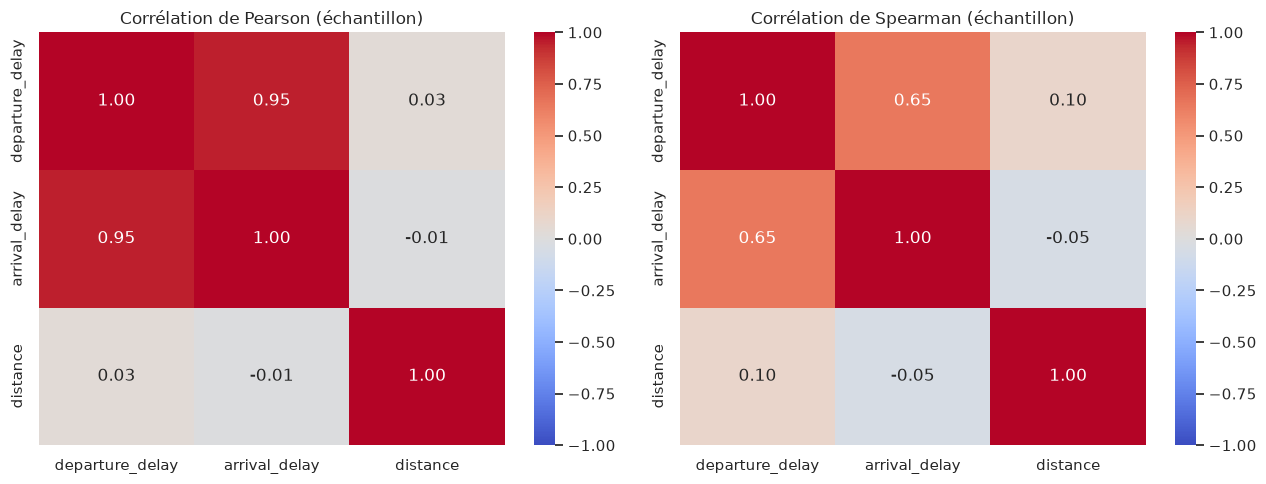

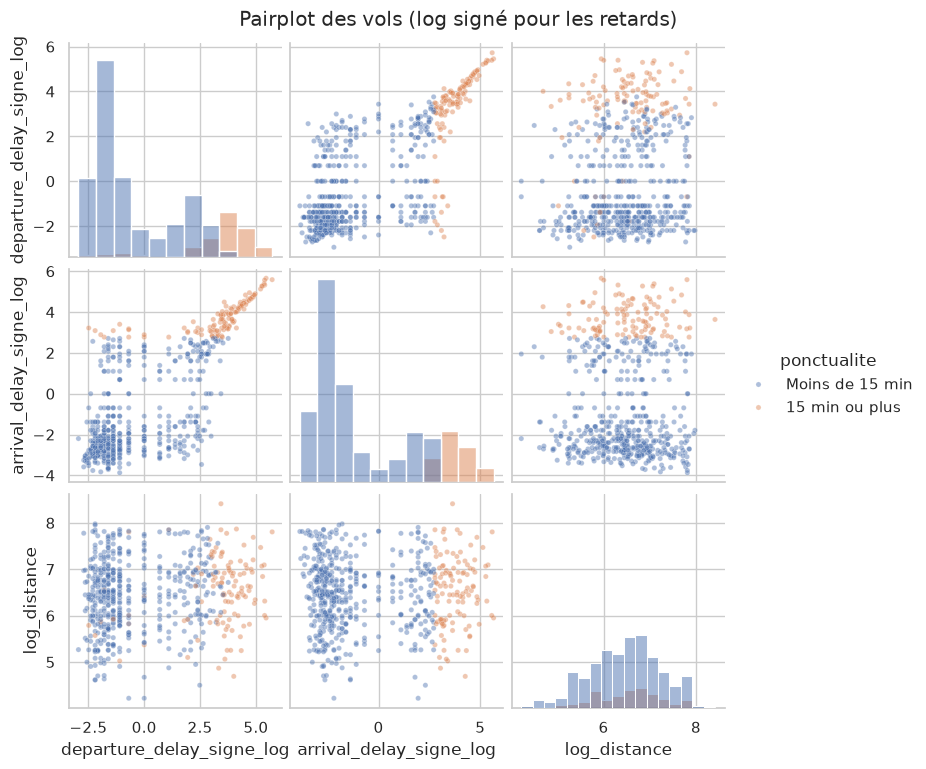

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


ACP : PC1 = 52.3 %, PC2 = 23.3 %, total = 75.6 % de variance expliquée


,PC1,PC2
depart_moyen,0.459,-0.458
arrivee_moyenne,0.553,-0.027
arrivee_mediane,0.388,0.493
retard_pct,0.543,-0.180
distance_moyenne,0.062,-0.025
weekend_pct,0.186,0.716


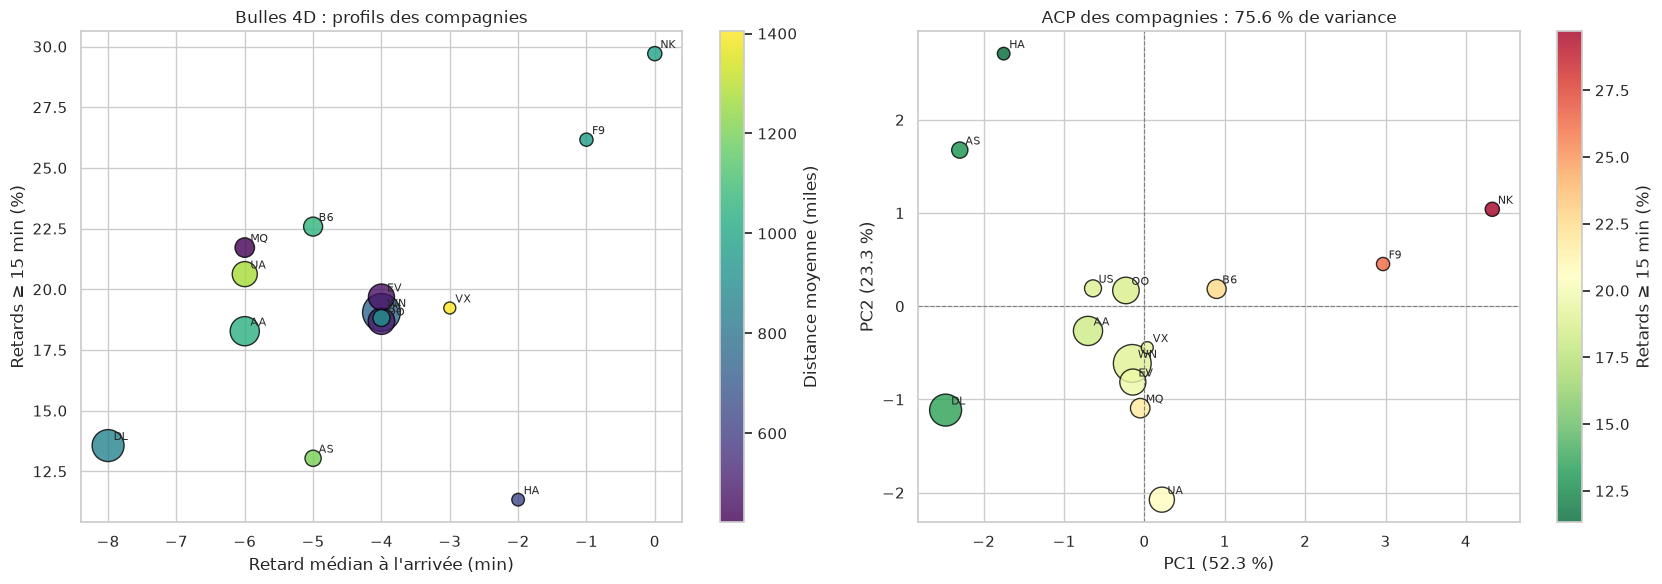

In [9]:
corr_cols = ["departure_delay", "arrival_delay", "distance"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ("pearson", "spearman")):
    sns.heatmap(sample_pd[corr_cols].corr(method=method), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax)
    ax.set_title(f"Corrélation de {method.capitalize()} (échantillon)")
plt.tight_layout()
plt.show()
pair_pd = sample_pd.sample(n=min(600, len(sample_pd)), random_state=42).copy()
for column in ("departure_delay", "arrival_delay"):
    pair_pd[column + "_signe_log"] = np.sign(pair_pd[column]) * np.log1p(np.abs(pair_pd[column]))
pair_pd["log_distance"] = np.log1p(pair_pd["distance"])
pair_pd["ponctualite"] = np.where(pair_pd["is_late"], "15 min ou plus", "Moins de 15 min")
g = sns.pairplot(pair_pd, vars=["departure_delay_signe_log", "arrival_delay_signe_log", "log_distance"], hue="ponctualite", diag_kind="hist", plot_kws={"alpha": 0.45, "s": 14})
g.figure.suptitle("Pairplot des vols (log signé pour les retards)", y=1.02)
plt.show()

profiles = (eda_flights.groupBy("airline").agg(
    F.count("*").alias("vols"),
    F.avg("departure_delay").alias("depart_moyen"),
    F.avg("arrival_delay").alias("arrivee_moyenne"),
    F.percentile_approx("arrival_delay", 0.5, 10000).alias("arrivee_mediane"),
    (100 * F.avg(F.col("is_late").cast("double"))).alias("retard_pct"),
    F.avg("distance").alias("distance_moyenne"),
    (100 * F.avg(F.col("is_weekend").cast("double"))).alias("weekend_pct"),
).orderBy(F.desc("vols")).toPandas())
features = ["depart_moyen", "arrivee_moyenne", "arrivee_mediane", "retard_pct", "distance_moyenne", "weekend_pct"]
if len(profiles) < 2 or profiles[features].isna().any().any():
    raise ValueError("ACP impossible : au moins deux compagnies avec six indicateurs complets sont nécessaires.")
scaled = StandardScaler().fit_transform(profiles[features])
pca = PCA(n_components=2)
coords = pca.fit_transform(scaled)
profiles[["PC1", "PC2"]] = coords
explained = pca.explained_variance_ratio_ * 100
print(f"ACP : PC1 = {explained[0]:.1f} %, PC2 = {explained[1]:.1f} %, total = {explained.sum():.1f} % de variance expliquée")
display(pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sizes = 40 + 700 * profiles["vols"] / profiles["vols"].max()
bubble = axes[0].scatter(profiles["arrivee_mediane"], profiles["retard_pct"], s=sizes, c=profiles["distance_moyenne"], cmap="viridis", alpha=0.8, edgecolors="black")
axes[0].set(title="Bulles 4D : profils des compagnies", xlabel="Retard médian à l'arrivée (min)", ylabel="Retards ≥ 15 min (%)")
fig.colorbar(bubble, ax=axes[0], label="Distance moyenne (miles)")
projection = axes[1].scatter(profiles["PC1"], profiles["PC2"], s=sizes, c=profiles["retard_pct"], cmap="RdYlGn_r", alpha=0.8, edgecolors="black")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set(title=f"ACP des compagnies : {explained.sum():.1f} % de variance", xlabel=f"PC1 ({explained[0]:.1f} %)", ylabel=f"PC2 ({explained[1]:.1f} %)")
fig.colorbar(projection, ax=axes[1], label="Retards ≥ 15 min (%)")
for _, row in profiles.iterrows():
    axes[0].annotate(row["airline"], (row["arrivee_mediane"], row["retard_pct"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    axes[1].annotate(row["airline"], (row["PC1"], row["PC2"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()

#### Relations entre variables et profils des compagnies

Les retards au départ et à l’arrivée sont fortement associés dans l’échantillon (**Pearson 0,95**, **Spearman 0,65**). Le pairplot montre un alignement particulièrement net pour les grands retards et davantage de dispersion autour des petits retards et des avances. Le seuil de 15 min définit les couleurs du pairplot, ce qui explique la séparation sur l’axe du retard à l’arrivée. La distance est très faiblement corrélée au retard à l’arrivée (**Pearson −0,01**, **Spearman −0,05**).

Le graphique à bulles montre que la médiane et le taux de retard décrivent deux aspects de la ponctualité. HA affiche une médiane d’environ **−2 min** et un taux d’environ **11 %**, tandis que MQ combine une médiane de **−6 min** et un taux proche de **22 %**. NK et F9 présentent les taux les plus élevés, autour de **30 %** et **26 %**. Ces compagnies exploitent des volumes et des réseaux de liaisons différents.

Les deux premiers axes de l’ACP résument **75,6 %** de la variance des six indicateurs standardisés par compagnie. **PC1 (52,3 %)** est surtout associé au retard moyen à l’arrivée et à la part de vols retardés d’au moins 15 min, ce qui situe NK et F9 à droite du graphique. **PC2 (23,3 %)** est principalement associé à la part de vols le week-end, puis à la médiane à l’arrivée et au retard moyen au départ, ce dernier contribuant en sens opposé. Chaque compagnie a le même poids dans le calcul de l’ACP.

### 4.4 Analyse des causes déclarées des retards

Nous cherchons à identifier les principales causes des retards à l'arrivée des vols américains en 2015.

L'analyse porte sur les vols non annulés ayant au moins 15 minutes de retard à l'arrivée.

In [10]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Les cinq causes de retard
delay_causes = {
    "airline_delay": "Compagnie aérienne",
    "weather_delay": "Météo",
    "air_system_delay": "Système aérien",
    "security_delay": "Sécurité",
    "late_aircraft_delay": "Arrivée tardive de l'avion"
}

# Sélection des vols arrivés avec au moins 15 minutes de retard
delayed_flights = silver.filter(
    (F.col("cancelled") == 0) &
    (F.col("arrival_delay") >= 15)
)

# Conserver uniquement les vols dont les cinq causes sont renseignées
documented_flights = delayed_flights.dropna(
    subset=list(delay_causes.keys())
)

total_delayed = delayed_flights.count()
total_documented = documented_flights.count()

print(f"Vols en retard : {total_delayed:,}")
print(f"Vols avec causes renseignées : {total_documented:,}")
print(f"Dossiers incomplets : {total_delayed - total_documented:,}")

# Calculer le nombre de minutes attribuées à chaque cause
result = documented_flights.agg(
    *[
        F.sum(F.col(col)).alias(col)
        for col in delay_causes
    ]
).first()

# Préparer les résultats
cause_minutes = {
    label: result[col] or 0
    for col, label in delay_causes.items()
}

total_minutes = sum(cause_minutes.values())

cause_percentages = {
    cause: (minutes / total_minutes * 100)
    if total_minutes else 0
    for cause, minutes in cause_minutes.items()
}

# Afficher les résultats
for cause, percentage in sorted(
    cause_percentages.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{cause} : {percentage:.2f} %")

Vols en retard : 1,063,439
Vols avec causes renseignées : 1,063,439
Dossiers incomplets : 0
Arrivée tardive de l'avion : 39.84 %
Compagnie aérienne : 32.20 %
Système aérien : 22.88 %
Météo : 4.95 %
Sécurité : 0.13 %


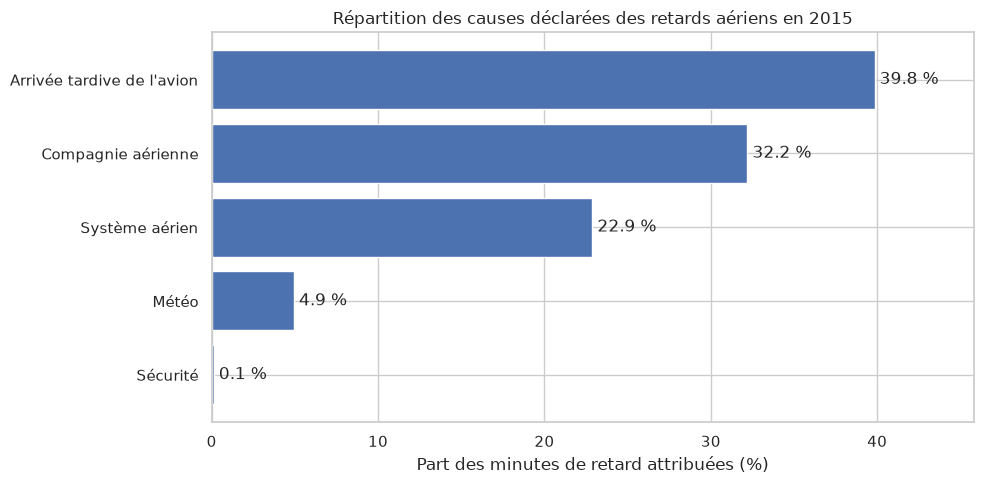

In [11]:
# Trier les causes par importance
sorted_causes = sorted(
    cause_percentages.items(),
    key=lambda item: item[1]
)

labels = [item[0] for item in sorted_causes]
values = [item[1] for item in sorted_causes]

plt.figure(figsize=(10, 5))

plt.barh(labels, values)

plt.xlabel("Part des minutes de retard attribuées (%)")
plt.title("Répartition des causes déclarées des retards aériens en 2015")

for i, value in enumerate(values):
    plt.text(value + 0.3, i, f"{value:.1f} %", va="center")

plt.xlim(0, max(values) * 1.15 if values else 1)
plt.tight_layout()
plt.show()

#### Lecture des graphiques

Afin de mieux comprendre l'origine des retards aériens, nous avons étudié les cinq catégories de causes présentes dans notre dataset : compagnie aérienne, météo, système aérien, sécurité et arrivée tardive de l'appareil.

L'analyse porte sur les vols non annulés arrivés avec **au moins 15 minutes de retard** et pour lesquels **les cinq causes sont renseignées**.

**Répartition des minutes de retard attribuées**

- **39,8 %** des minutes de retard attribuées sont liées à l'arrivée tardive de l'avion utilisé.
- **32,2 %** sont attribuées à la compagnie aérienne.
- **22,9 %** sont liées au système aérien.
- Les conditions météorologiques et les problèmes de sécurité représentent ensemble **5,1 %** des minutes attribuées.

**Interprétation**

L'arrivée tardive de l'appareil constitue donc la principale cause déclarée parmi les catégories étudiées.

Ce résultat suggère un phénomène de propagation des retards : lorsqu'un avion arrive en retard, son prochain départ peut également être retardé, entraînant potentiellement des perturbations sur les vols suivants.

Cette analyse complète notre observation précédente concernant la forte corrélation entre les retards au départ et à l'arrivée.

**Limites**

Ces résultats reposent sur les minutes attribuées aux différentes catégories et non sur le nombre de vols concernés. Ils ne permettent pas à eux seuls d'établir toutes les relations de causalité entre les retards.

## 5. Conclusion générale

Cette analyse exploratoire des vols intérieurs américains de 2015, réalisée avec Apache Spark et Delta Lake, nous a permis d'étudier la qualité des données, de préparer une couche Silver exploitable et d'identifier plusieurs tendances concernant les retards aériens.

### Qualité et préparation des données

Le nettoyage des données a permis de contrôler les valeurs manquantes, les doublons et les anomalies, tout en conservant les informations pertinentes pour l'analyse. Les retards non renseignés, notamment pour les vols annulés, n'ont pas été remplacés artificiellement afin de ne pas fausser les résultats.

Les valeurs extrêmes ont également été conservées, mais identifiées à l'aide de la méthode de l'écart interquartile (IQR).

### Principaux résultats

L'analyse des **5 714 008 vols non annulés dont le retard à l'arrivée est renseigné** met en évidence plusieurs observations :

- **Ponctualité :** 81,4 % des vols arrivent avec moins de 15 minutes de retard. La médiane de −5 minutes indique qu'un vol arrive généralement légèrement en avance, tandis que la moyenne de +4,41 minutes est influencée par les retards importants.
- **Retards au départ :** dans l'échantillon, les retards au départ et à l'arrivée sont fortement corrélés (Pearson = 0,95). Les vols qui décollent en retard ont donc généralement tendance à arriver également en retard.
- **Distance parcourue :** dans l'échantillon, la distance présente une très faible corrélation avec le retard à l'arrivée (Pearson = −0,01). Elle ne semble donc pas constituer, à elle seule, un indicateur pertinent du retard.
- **Variations temporelles :** le taux de retard varie selon les mois, avec un maximum d'environ 23,5 % en juin et un minimum d'environ 12,4 % en octobre.
- **Compagnies aériennes :** certaines compagnies présentent des taux de retard plus élevés que d'autres. Toutefois, ces écarts peuvent également dépendre des trajets et des conditions d'exploitation.
- **Causes déclarées des retards :** parmi les vols retardés d'au moins 15 minutes dont les causes sont renseignées, l'arrivée tardive de l'appareil représente la part la plus importante des minutes attribuées (39,8 %), suivie des causes liées à la compagnie aérienne (32,2 %) et au système aérien (22,9 %). Ces résultats suggèrent notamment un phénomène de propagation des retards entre les vols successifs d'un même appareil.

### Limites de l'analyse

Ces résultats mettent en évidence des associations statistiques, mais ne permettent pas d'établir des relations de causalité.

De plus, les données concernent uniquement l'année 2015. Il serait nécessaire d'étudier plusieurs années pour confirmer d'éventuelles tendances saisonnières.

Enfin, l'analyse des causes repose sur les minutes de retard déclarées et non sur le nombre de vols concernés.

### Perspectives

Cette étude pourrait être prolongée par une analyse plus détaillée des différences de ponctualité entre compagnies, en tenant compte des trajets et des aéroports desservis.

Les données préparées dans la couche Silver constituent également une base exploitable pour les prochaines étapes du projet, notamment les analyses statistiques avancées et la construction éventuelle d'un modèle prédictif des retards aériens.

**En conclusion, cette étude montre l'intérêt d'une architecture Data Lakehouse associée à Apache Spark pour nettoyer, enrichir et analyser un volume important de données, tout en préservant leur qualité et leur traçabilité.**

In [ ]:
from pyspark.sql import functions as F

df_check = spark.read.format("delta").load(
    "hdfs://namenode:9000/lakehouse/silver/flights_enriched"
)

df_check.select(
    "origin_weather_station_id",
    "air_temperature_c",
    "wind_speed_mps",
    "precipitation_1h_mm"
).filter(
    F.col("air_temperature_c").isNotNull()
).show(5, truncate=False)

+-------------------------+-----------------+--------------+-------------------+
|origin_weather_station_id|air_temperature_c|wind_speed_mps|precipitation_1h_mm|
+-------------------------+-----------------+--------------+-------------------+
|700260-27502             |-29.4            |6.2           |0.0                |
|700260-27502             |-11.7            |5.7           |0.0                |
|700260-27502             |-21.1            |3.6           |0.0                |
|700260-27502             |-6.7             |14.9          |0.0                |
|700260-27502             |-6.1             |12.9          |0.0                |
+-------------------------+-----------------+--------------+-------------------+
only showing top 5 rows


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 43074)
Traceback (most recent call last):
  File "/opt/python/cpython-3.15.2-linux-x86_64-gnu/lib/python3.15/socketserver.py", line 315, in _handle_request_noblock
    self.process_request(request, client_address)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/python/cpython-3.15.2-linux-x86_64-gnu/lib/python3.15/socketserver.py", line 346, in process_request
    self.finish_request(request, client_address)
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/python/cpython-3.15.2-linux-x86_64-gnu/lib/python3.15/socketserver.py", line 359, in finish_request
    self.RequestHandlerClass(request, client_address, self)
    ~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/python/cpython-3.15.2-linux-x86_64-gnu/lib/python3.15/socketserver.py", line 763, in __init__
    self.handle()
    ~~~~~~~~~~~^^
  File "/opt/venv/lib/python3.15/site-pa

## Validation de la couche Silver

Les traitements Spark ont permis de nettoyer et d'enrichir les données des vols.

La table Silver est stockée au format Delta Lake dans HDFS.

L'exécution contrôlée le 19 novembre 2026 a produit 177 jobs Spark réussis, sans échec.

La version 4 de la table Delta contient 81 colonnes, dont les attributs météorologiques provenant du dataset NOAA.

L'enrichissement météorologique a été intégré afin de permettre l'analyse des relations entre les conditions météo et les retards aériens.